# GSU Analytics Skills Assessment

**Venkata Simha Reddy Desuri** · November 2026

## Summary

- **Question 1:** There are **10,000 students**. I also checked that no student ID appears twice.
- **Question 2:** **74 students** are Pell Grant recipients with an email and a last name starting with "A".
- **Question 3:** Courses must be matched on section code **and** term. One section code is reused in two terms, so matching on section code alone creates **409 wrong extra rows**.
- **Bar chart:** Average credits fell from about **6 to 4.2** after 2023. Students still take about 3 courses each term; the courses now carry fewer credits.
- **My analysis:** Students with special labels seem to earn lower grades, but they are really two groups. **ESL students average about 2.0**, **Honors students about 3.4**, and everyone else about 3.0. ESL students may need more support.

*I used an AI assistant to help with code. The choices and conclusions are mine, and I'm happy to walk through any of them.*

In [1]:
#################################
# RUN ME FIRST TO LOAD FILES    #
#################################

!git clone https://github.com/GSU-Analytics/assessment

Cloning into 'assessment'...


remote: Enumerating objects: 39, done.
remote: Counting objects: 100% (39/39), done.
remote: Compressing objects: 100% (28/28), done.


remote: Total 39 (delta 16), reused 32 (delta 9), pack-reused 0 (from 0)
Receiving objects: 100% (39/39), 4.68 MiB | 26.61 MiB/s, done.
Resolving deltas: 100% (16/16), done.


# Introduction

Welcome to the skill assessment notebook. These exercises evaluate your proficiency in SQL, Python, and data analysis.

You can skip questions without penalty. Use resources like Google, code samples, or AI tools, but be ready to discuss your answers and approach during the interview.

For questions, contact Isaac at ikerson@gsu.edu. Once finished, save the notebook and share the link with Isaac. We look forward to seeing your work!

# Overview of `university.db`

The `university.db` database is a mock SQLite database designed to simulate a collection of university data tables. It contains information about students, instructors, courses, grades, and more. This database is structured to provide realistic data for demonstrating data analysis skills.

## Database Schema

The database consists of the following tables:

### 1. **`student_main`**
- **Description**: Stores detailed information about students enrolled at the university.
- **Key Columns**:
  - `student_id`: Unique identifier for each student (primary key).
  - `last_name`, `first_name`, `middle_initial`: Student's name details.
  - `email`: Student's email address (not every student has one).
  - `gender`, `ethnicity`: Demographic information.
  - `address`, `us_citizen`, `us_resident`, `state_resident`: Residential and citizenship details. The citizen and resident columns are `Y` or `N`.
  - `pell_recipient`, `us_veteran`: Pell Grant recipient and veteran status, stored as `Y` or `N`.
- **Relationships**:
  - Linked to `student_grades` through `student_id`.
  - Linked to `student_attributes` through `student_id`.

### 2. **`instructor_main`**
- **Description**: Contains information about university instructors.
- **Key Columns**:
  - `employee_id`: Unique identifier for each instructor (primary key).
  - `last_name`, `first_name`: Instructor's name details.
  - `faculty_code`: Foreign key referencing `faculty_code_validation_table.faculty_code`, representing the faculty type (e.g., tenure-track, adjunct).
  - `full_time_indicator`: Binary indicator for full-time (1) or part-time (0) status.
- **Relationships**:
  - Linked to `courses` through `employee_id`.

### 3. **`faculty_code_validation_table`**
- **Description**: A lookup table that validates and describes faculty codes.
- **Key Columns**:
  - `faculty_code`: Three-letter code for faculty type (primary key).
  - `faculty_description`: Description of the faculty type.

### 4. **`courses`**
- **Description**: Represents the courses offered at the university.
- **Key Columns**:
  - `id`: Unique identifier for each course section (primary key).
  - `term_code`: Academic term as YYYYMM: `01` Spring, `05` Summer, `08` Fall (e.g., `202308` is Fall 2023).
  - `major_abbreviation`, `department_code`: Subject and department offering the course (e.g., MATH, BIO).
  - `course_number`, `section_code`: Course and section identifiers. A `section_code` is unique only within a term; the same code can appear in different terms.
  - `location_code`: Location where the course is held.
  - `delivery_code`: Mode of instruction (`I` In-person, `H` Hybrid, `O` Online).
  - `time`: Class start time (24-hour, e.g., `13:30`).
  - `monday` through `sunday`: 1 if the class meets that day, 0 otherwise.
  - `credits`: Number of credit hours assigned to the course (1–3).
  - `employee_id`: Foreign key referencing `instructor_main.employee_id`, indicating the instructor teaching the course.
- **Relationships**:
  - Linked to `instructor_main` through `employee_id`.
  - Linked to `student_grades` through `section_code` and `term_code`.

### 5. **`student_grades`**
- **Description**: Records students' grades for courses.
- **Key Columns**:
  - `id`: Unique identifier for each grade record (primary key).
  - `student_id`: Foreign key referencing `student_main.student_id`.
  - `term_code`: Term during which the grade was earned.
  - `section_code`: References `courses.section_code`; match on `term_code` as well.
  - `grade`: Grade points received for the course, from 0.0 to 4.0, stored as text. Missing when the student withdrew.
  - `withdrawal`: Binary indicator for course withdrawal (1 for withdrawal, 0 otherwise).
- **Relationships**:
  - Linked to `student_main` through `student_id`.
  - Linked to `courses` through `section_code` and `term_code`.

### 6. **`student_attributes`**
- **Description**: Tracks additional attributes assigned to students for specific terms.
- **Key Columns**:
  - `id`: Unique identifier for each attribute record (primary key).
  - `student_id`: Foreign key referencing `student_main.student_id`.
  - `term_code`: Academic term for which the attribute applies.
  - `attribute_code`: Foreign key referencing `attribute_code_validation_table.attribute_code`, indicating the assigned attribute (e.g., ESL, Honors).
- **Relationships**:
  - Linked to `student_main` through `student_id`.
  - Linked to `attribute_code_validation_table` through `attribute_code`.

### 7. **`attribute_code_validation_table`**
- **Description**: A lookup table that validates and describes student attribute codes.
- **Key Columns**:
  - `attribute_code`: Three-letter code for student attributes (primary key).
  - `attribute_description`: Description of the attribute.

## Relationships Between Tables

The tables and relationships in the `university.db` database detailed in the following schema diagram:

![University Database Schema](https://raw.githubusercontent.com/GSU-Analytics/assessment/main/schema_diagram.png)


### Introduction to Pandas and the `read_sql` Method

**Pandas** is a powerful Python library for data manipulation and analysis. It provides easy-to-use data structures like DataFrames and Series, which allow for efficient handling and processing of structured data. Pandas is widely used in data science, machine learning, and data analytics.

One of Pandas' strengths is its ability to seamlessly interact with SQL databases, enabling you to load query results directly into a DataFrame using the `read_sql` method. This method simplifies the process of querying databases and analyzing the results in Python.

#### What is `read_sql`?
The `pandas.read_sql()` method allows you to execute SQL queries on a database and retrieve the results as a Pandas DataFrame. It can be used to:
1. Query data from a database.
2. Load entire tables into a DataFrame.
3. Perform complex SQL queries and integrate results with Python-based analysis.

#### Basic Syntax
```python
pandas.read_sql(sql, con, index_col=None, coerce_float=True, params=None)
```

- **`sql`**: The SQL query or table name as a string.
- **`con`**: A database connection object (e.g., SQLAlchemy engine).
- **`index_col`**: Column(s) to set as the DataFrame index (optional).
- **`params`**: Parameters to pass for parameterized queries (optional).

#### Benefits of Using `read_sql`
- Directly integrates SQL querying into your Python workflow.
- Returns a DataFrame, which is ideal for further analysis and visualization in Python.
- Supports parameterized queries for added security and flexibility.

#### Documentation
For a complete guide to the `read_sql` method, visit the [Pandas Documentation](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_sql.html). 

This page provides detailed explanations, parameters, and examples to help you make the most of this method.

In [2]:
# Run the following cell for an example how to use `pd.read_sql`

import os
import pandas as pd
from sqlalchemy import create_engine

# Find the database: Colab clone, repository root, or the assessment folder
candidates = ["/content/assessment/university.db", "assessment/university.db", "university.db"]
DATABASE_FILE = next((p for p in candidates if os.path.exists(p)), None)
if DATABASE_FILE is None:
    raise FileNotFoundError("university.db not found. Run the first cell to clone the repository.")

# Define the database URL
DATABASE_URL = f"sqlite:///{DATABASE_FILE}"

# Create the engine to connect to the database
engine = create_engine(DATABASE_URL)

# Test the connection by running a query to get table names
query = "SELECT name FROM sqlite_master where type = 'table';"
tables = pd.read_sql(query, engine)

# Print the list of tables
print("Connected to the database!")
print("Tables in the database:")
display(tables)

Connected to the database!
Tables in the database:


,name
0,student_main
1,faculty_code_validation_table
2,attribute_code_validation_table
3,instructor_main
4,student_attributes
5,courses
6,student_grades


### Count the Total Number of Students

#### Directions:
Write a SQL query in the space provided below to count the total number of students in the database. Use the `student_main` table for this task. Then run the cell to execute your query and display the result.

In [3]:
## Complete the query to get the number of students in the `student_main` table
student_count_query = """
SELECT COUNT(*)                   AS student_count,
       COUNT(DISTINCT student_id) AS distinct_student_ids   -- check: is every student_id unique?
FROM student_main;
"""

## Do not edit the code below
student_count_df = pd.read_sql(student_count_query, engine)

# Display the result
display(student_count_df)

,student_count,distinct_student_ids
0,10000,10000


**Answer: 10,000 students.** I also counted distinct `student_id`s to confirm the primary key has no duplicates, so the row count really is a student count.

### Get the Records of Pell Grant Recipients with an Email and a Last Name Starting with "A"

#### Directions:
Write a SQL query in the space provided below to retrieve the records of students who are Pell Grant recipients and have an email value as well a last name starting with the letter "A". Use the `student_main` table and filter on the `last_name`, `email`, and `pell_recipient` columns. Return the `student_id`, `last_name`, `first_name`, `email`, and `address` for each student. Then run the cell to execute your query and display the results.

In [4]:
## Complete the query to get Pell Grant Recipients with a Last Name Starting with "A"
pell_grant_query = """
SELECT student_id, last_name, first_name, email, address
FROM student_main
WHERE pell_recipient = 'Y'
  AND email IS NOT NULL
  AND TRIM(email) <> ''          -- also exclude blank strings, not just NULLs
  AND last_name LIKE 'A%'        -- SQLite LIKE is case-insensitive for ASCII
ORDER BY last_name, first_name;
"""

## Do not edit the code below
pell_grant_df = pd.read_sql(pell_grant_query, engine)

# Display the result
display(pell_grant_df.head())

,student_id,last_name,first_name,email,address
0,410052661,Abbott,Daniel,jamesdennis@example.org,"344 West Junction Suite 424, Mullinsburgh, NV ..."
1,286893653,Abbott,Joel,rgamble@example.org,"08955 Mary Expressway Apt. 518, South Rhondato..."
2,248750952,Abbott,Joel,cathy59@example.com,"099 Jon Fork, Davidmouth, MP 85526"
3,184607484,Abbott,Traci,ronaldmckay@example.com,"463 Winters Village, Jacksonland, DC 26959"
4,290091367,Acosta,Chris,donnaolson@example.com,"3226 Steven Crescent, East Lisastad, VI 45945"


In [5]:
# How many rows matched, and how does each filter narrow the population?
funnel = pd.read_sql("""
SELECT COUNT(*)                                                       AS all_students,
       SUM(pell_recipient = 'Y')                                      AS pell,
       SUM(pell_recipient = 'Y' AND email IS NOT NULL AND TRIM(email) <> '') AS pell_with_email,
       SUM(pell_recipient = 'Y' AND email IS NOT NULL AND TRIM(email) <> ''
           AND last_name LIKE 'A%')                                   AS pell_email_last_A
FROM student_main;
""", engine)
display(funnel)
print(f"Rows returned by the query: {len(pell_grant_df)}")

,all_students,pell,pell_with_email,pell_email_last_A
0,10000,2539,2034,74


Rows returned by the query: 74


Notes on the approach:
- "Has an email" is checked as `IS NOT NULL` **and** non-blank. In this database the missing emails are all true `NULL`s, but checking for blanks too costs nothing and protects against a common data-entry pattern.
- The funnel shows how each filter narrows the population, which makes the final count easy to check.

### Get the Average Credits per Student in Each Term

#### Directions:
Write a SQL query in the space provided below to calculate, for each term, the average number of credits a student took. First total each student's credits in the term, then average those totals across students. Use the `student_grades` and `courses` tables. Return `term_code` and `average_credits`, ordered by `term_code`. Then run the cell to execute your query and display the result.

In [6]:
## Complete the query to get the average credits per student in each term
average_credits_query = """
WITH student_term_credits AS (
    -- Step 1: total credits per student per term
    SELECT g.term_code,
           g.student_id,
           SUM(c.credits) AS total_credits
    FROM student_grades g
    JOIN courses c
      ON  c.section_code = g.section_code
      AND c.term_code    = g.term_code      -- section codes are only unique within a term
    GROUP BY g.term_code, g.student_id
)
-- Step 2: average those totals across students in each term
SELECT term_code,
       AVG(total_credits) AS average_credits
FROM student_term_credits
GROUP BY term_code
ORDER BY term_code;
"""

## Do not edit the code below
average_credits_df = pd.read_sql(average_credits_query, engine)

# Display the result
display(average_credits_df)

,term_code,average_credits
0,201901,6.494505
1,201905,6.524377
2,201908,5.956522
3,202001,6.251951
4,202005,6.201525
5,202008,6.278602
6,202101,6.396721
7,202105,5.476489
8,202108,6.448037
9,202201,5.973176


#### Checking the join and the assumptions

Two decisions in this query matter, so I tested both:

1. **Join on `section_code` *and* `term_code`.** The schema notes say a section code is only unique within a term. The check below shows what happens if you join on `section_code` alone: one code is reused across two terms, so 409 grade rows get duplicated onto the wrong section and the credit totals are inflated.
2. **Withdrawals are included.** I read "credits a student took" as *attempted* credits (the student registered for the course), which is how enrollment and credit load are usually reported. The second check shows the result if withdrawn courses are excluded instead, i.e. "credits completed". The difference is small, and the trend over time is the same.

In [7]:
checks = pd.read_sql("""
SELECT
  (SELECT COUNT(*) FROM student_grades)                                            AS grade_rows,
  (SELECT COUNT(*) FROM student_grades g JOIN courses c
       ON c.section_code = g.section_code AND c.term_code = g.term_code)          AS rows_correct_join,
  (SELECT COUNT(*) FROM student_grades g JOIN courses c
       ON c.section_code = g.section_code)                                          AS rows_section_only_join,
  (SELECT COUNT(*) FROM (SELECT section_code FROM courses
       GROUP BY section_code HAVING COUNT(DISTINCT term_code) > 1))                 AS section_codes_reused
""", engine)
display(checks)

completed_only = pd.read_sql("""
WITH stc AS (
    SELECT g.term_code, g.student_id, SUM(c.credits) AS total_credits
    FROM student_grades g
    JOIN courses c ON c.section_code = g.section_code AND c.term_code = g.term_code
    WHERE g.withdrawal = 0
    GROUP BY g.term_code, g.student_id
)
SELECT term_code, AVG(total_credits) AS avg_credits_completed
FROM stc GROUP BY term_code ORDER BY term_code
""", engine)

compare = average_credits_df.merge(completed_only, on="term_code")
compare["difference"] = compare["average_credits"] - compare["avg_credits_completed"]
display(compare.round(3))

,grade_rows,rows_correct_join,rows_section_only_join,section_codes_reused
0,50000,50000,50409,1


,term_code,average_credits,avg_credits_completed,difference
0,201901,6.495,6.222,0.273
1,201905,6.524,6.248,0.276
2,201908,5.957,5.740,0.216
3,202001,6.252,6.001,0.251
4,202005,6.202,5.916,0.286
5,202008,6.279,6.099,0.180
6,202101,6.397,6.113,0.284
7,202105,5.476,5.257,0.220
8,202108,6.448,6.170,0.278
9,202201,5.973,5.734,0.239


## Create a Bar Plot of Average Credits Over Time

#### Directions:
Using the results from the previous query, create a bar plot showing the average credits per student over time. The x-axis should represent the term code, and the y-axis should display the average credits per student. Label the axes appropriately and provide a title for the plot. You can use any Python data visualization library you prefer (e.g., Matplotlib, Seaborn, etc.).

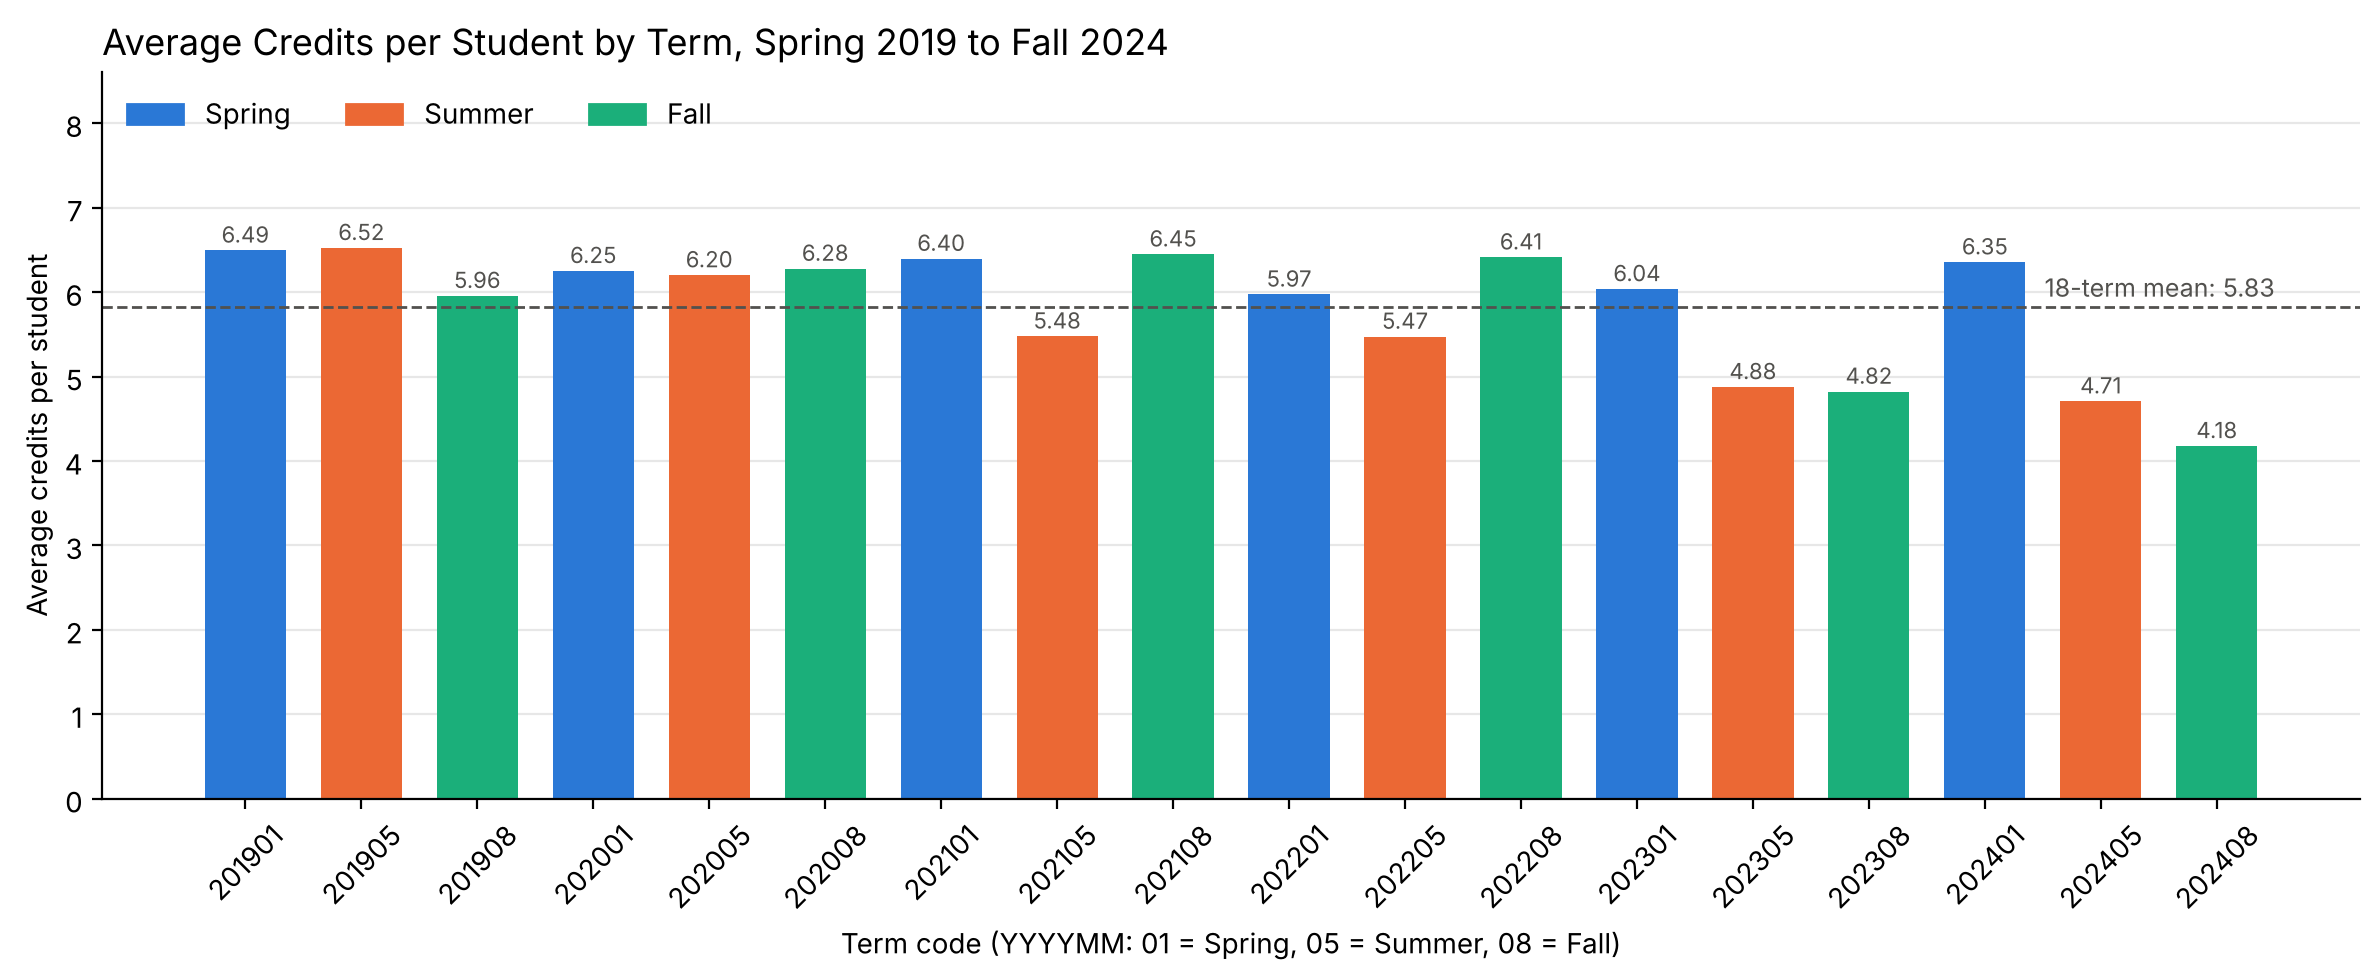

In [8]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

plot_df = average_credits_df.copy()
season_names = {"01": "Spring", "05": "Summer", "08": "Fall"}
plot_df["season"] = plot_df["term_code"].str[-2:].map(season_names)

# Color by season so seasonal patterns are visible at a glance
season_colors = {"Spring": "#2a78d6", "Summer": "#eb6834", "Fall": "#1baf7a"}
colors = plot_df["season"].map(season_colors)

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(plot_df["term_code"], plot_df["average_credits"], color=colors, width=0.7)

# Overall mean as a reference line
overall = plot_df["average_credits"].mean()
ax.axhline(overall, color="#52514e", linestyle="--", linewidth=1)
ax.text(len(plot_df) - 0.5, overall + 0.05, f"18-term mean: {overall:.2f}",
        ha="right", va="bottom", fontsize=9, color="#52514e")

# Value labels on each bar
for bar, val in zip(bars, plot_df["average_credits"]):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.03, f"{val:.2f}",
            ha="center", va="bottom", fontsize=8, color="#52514e")

ax.set_title("Average Credits per Student by Term, Spring 2019 to Fall 2024", fontsize=13, loc="left")
ax.set_xlabel("Term code (YYYYMM: 01 = Spring, 05 = Summer, 08 = Fall)")
ax.set_ylabel("Average credits per student")
ax.set_ylim(0, plot_df["average_credits"].max() * 1.32)   # bars start at zero; headroom for legend
ax.tick_params(axis="x", rotation=45)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(handles=[mpatches.Patch(color=c, label=s) for s, c in season_colors.items()],
          frameon=False, loc="upper left", ncol=3)

plt.tight_layout()
plt.show()

**What the chart shows:** from 2019 to 2022 the average load was steady at about 6 credits. Since Summer 2023 it has dropped in most terms, reaching **4.2 credits in Fall 2024**, the lowest in the series. Spring terms have stayed stable.

A drop like that could mean students are taking fewer courses, or that the courses carry fewer credits. Those lead to very different conclusions (a demand problem vs. a course-offering problem), so I split average credits into **courses per student × credits per course**:

In [9]:
decomp = pd.read_sql("""
WITH st AS (
    SELECT g.term_code, g.student_id, COUNT(*) AS n_courses, SUM(c.credits) AS credits
    FROM student_grades g
    JOIN courses c ON c.section_code = g.section_code AND c.term_code = g.term_code
    GROUP BY g.term_code, g.student_id
)
SELECT st.term_code,
       COUNT(*)                              AS students,
       AVG(n_courses)                        AS courses_per_student,
       SUM(credits) * 1.0 / SUM(n_courses)   AS credits_per_enrollment,
       AVG(credits)                          AS average_credits,
       (SELECT COUNT(*) FROM courses c WHERE c.term_code = st.term_code)                     AS sections_offered,
       (SELECT SUM(credits = 1) FROM courses c WHERE c.term_code = st.term_code)             AS one_credit_sections
FROM st GROUP BY st.term_code ORDER BY st.term_code
""", engine)
display(decomp.round(2))
print(decomp[["courses_per_student", "credits_per_enrollment", "average_credits"]].corr().round(2)["average_credits"])

,term_code,students,courses_per_student,credits_per_enrollment,average_credits,sections_offered,one_credit_sections
0,201901,910,3.02,2.15,6.49,7,2
1,201905,923,3.00,2.18,6.52,16,4
2,201908,920,2.99,1.99,5.96,21,8
3,202001,897,2.95,2.12,6.25,9,4
4,202005,918,3.09,2.00,6.20,12,4
5,202008,944,2.99,2.10,6.28,10,3
6,202101,915,3.06,2.09,6.40,12,3
7,202105,957,2.98,1.84,5.48,12,4
8,202108,866,3.06,2.11,6.45,13,4
9,202201,932,2.98,2.00,5.97,11,4


courses_per_student       0.04
credits_per_enrollment    0.99
average_credits           1.00
Name: average_credits, dtype: float64


**Takeaway:** students consistently take about **3 courses per term**; that number barely moves. The decline comes entirely from **credits per enrollment** (correlation with average credits ≈ 0.99), which fell from about 2.1 to 1.4 as recent terms offered more 1-credit sections. So the drop reflects **what was offered**, not students choosing lighter loads.

That distinction matters for decisions. If students rely on these courses to make progress toward a degree, a lighter credit mix could slow time to graduation, and it's worth raising with whoever plans the course schedule.

# Open-ended Analysis

### Directions

In this section, please explore the `university.db` database and conduct any additional analyses you find interesting. This is an opportunity to showcase your skills, creativity, and analytical thinking. Feel free to ask questions, propose new analyses, or present your findings in any format you prefer (e.g., tables, charts, written summaries).

You can use SQL queries, Python code, data visualizations, or any other tools you find suitable for the task. Your analysis can cover topics like student performance, course enrollment trends, faculty characteristics, or any other aspect of the university data.

### Possible Questions for Analysis

Below are some example questions you might explore. They are only suggestions. You are **not** obligated to answer all or any of them. Pick one or come up with your own question to answer.

#### Grade Analysis
- Are there particular **courses**, **instructors**, or **student populations** that have significant deviations in outcomes?
- How do **average grades** differ across terms, courses, or majors?
- What is the distribution of grades for students in honors (HNR) or English as a Second Language (ESL) programs?

#### Enrollment Patterns
- What are the **enrollment patterns** for courses by day and/or time?
- Which courses have the **highest or lowest enrollments** across all terms?
- How do enrollments differ across **delivery modes** (in-person, hybrid, online)?

#### Instructor Impact
- Do specific instructors have consistently **higher or lower average grades** in their courses?
- How do full-time versus part-time instructors differ in terms of course outcomes?

#### Term Trends
- Are there any **seasonal trends** in course enrollment or performance (e.g., spring vs. summer vs. fall)?
- What is the average number of courses taken by students in each term?

#### Student Demographics
- What percentage of students are enrolled in **honors** or **athletic programs** each term?
- How does student performance differ by **gender** or **ethnicity**?

#### Course Specific Analysis
- What is the **most common combination** of courses taken by students in a given term?
- How do **drop/withdrawal rates** vary by course, instructor, or term?

## My analysis: Why do students with special attributes earn lower grades?

**Summary of findings**

1. Most grade comparisons in this database are flat: delivery mode, instructor type, term, gender, ethnicity and Pell status differ by only a few hundredths of a grade point.
2. One comparison stands out. Grades earned in a term when the student holds an attribute (Honors, ESL, Athlete, and so on) average about **0.25 points lower** than all other grades.
3. That gap belongs to the **student**, not the term. When the same student is compared in terms with and without an attribute, there is no difference.
4. The "attribute" group is really **two opposite groups averaged together**. Students who were ever flagged **ESL** average around **2.0**, students ever flagged **Honors** average around **3.4**, and the other eight attributes look the same as students with no attributes (around **3.0**).

**Why it matters:** averaging those two groups together produces an "attribute students underperform" headline that doesn't describe anyone. The useful conclusion is that ESL students need support and Honors students outperform.

The steps below show how I got there.

### Step 1: Build one analysis table

Grades are stored as text, so I cast them to numbers. I also join on both `section_code` and `term_code` (see Q3). Withdrawn enrollments have no grade; they stay in the table so withdrawal rates can be measured, but they drop out of grade averages automatically.

In [10]:
import numpy as np
import seaborn as sns
from scipy import stats

enroll = pd.read_sql("""
SELECT g.student_id, g.term_code,
       CAST(g.grade AS REAL)  AS grade,
       g.withdrawal,
       c.major_abbreviation, c.delivery_code, c.credits, c.location_code,
       i.employee_id, i.faculty_code, i.full_time_indicator,
       s.gender, s.ethnicity, s.pell_recipient, s.us_veteran, s.state_resident
FROM student_grades g
JOIN courses c         ON c.section_code = g.section_code AND c.term_code = g.term_code
JOIN instructor_main i ON i.employee_id  = c.employee_id
JOIN student_main s    ON s.student_id   = g.student_id
""", engine)

enroll["season"] = enroll["term_code"].str[-2:].map(season_names)

attrs = pd.read_sql("SELECT student_id, term_code, attribute_code FROM student_attributes", engine)

# Does a student ever hold more than one attribute in the same term?
per_term = attrs.groupby(["student_id", "term_code"]).size()
print(f"Max attributes per student per term: {per_term.max()}")

enroll = enroll.merge(attrs, on=["student_id", "term_code"], how="left")
enroll["has_attr_this_term"] = enroll["attribute_code"].notna()

print(f"Enrollment rows: {len(enroll):,}  (matches the 50,000 grade records)")
print(f"Students with at least one enrollment: {enroll.student_id.nunique():,} of 10,000")
print(f"Withdrawals: {enroll.withdrawal.mean():.1%}")

Max attributes per student per term: 1
Enrollment rows: 50,000  (matches the 50,000 grade records)
Students with at least one enrollment: 3,708 of 10,000
Withdrawals: 5.0%


Two things stand out about the data itself:
- Only about **3,700 of the 10,000 students** have any grade records. The rest may be admitted but not enrolled, or enrolled outside this 2019–2024 window. That's worth asking about before reporting any per-student numbers.
- Each student holds at most one attribute per term, so joining attributes onto enrollments does not duplicate rows.

### Step 2: Broad scan. Where do grades differ?

Before picking a question, I compared the average grade across every category in the data (online vs in-person, gender, and so on). For each category I measured the gap between the highest and lowest group.

In [11]:
dims = {
    "Delivery mode": "delivery_code", "Faculty type": "faculty_code", "Full-time instructor": "full_time_indicator",
    "Season": "season", "Term": "term_code", "Subject": "major_abbreviation", "Location": "location_code",
    "Credits": "credits", "Gender": "gender", "Ethnicity": "ethnicity", "Pell recipient": "pell_recipient",
    "Veteran": "us_veteran", "In-state resident": "state_resident", "Has attribute this term": "has_attr_this_term",
}
rows = []
for label, col in dims.items():
    avg = enroll.groupby(col)["grade"].mean()
    rows.append({"dimension": label, "groups": len(avg), "grade_spread": avg.max() - avg.min()})
scan = pd.DataFrame(rows).sort_values("grade_spread", ascending=False).reset_index(drop=True)
display(scan.round(3))

# Individual instructors: are some much harder or easier graders?
inst = enroll.groupby("employee_id")["grade"].mean()
print(f"Instructors: {len(inst)}  |  average grade ranges {inst.min():.2f} to {inst.max():.2f}  |  standard deviation {inst.std():.3f}")

,dimension,groups,grade_spread
0,Has attribute this term,2,0.245
1,Term,18,0.053
2,Veteran,2,0.042
3,Subject,10,0.031
4,Pell recipient,2,0.024
5,Faculty type,6,0.016
6,Gender,3,0.016
7,Ethnicity,5,0.012
8,Season,3,0.011
9,Location,5,0.009


Instructors: 88  |  average grade ranges 2.79 to 2.93  |  standard deviation 0.031


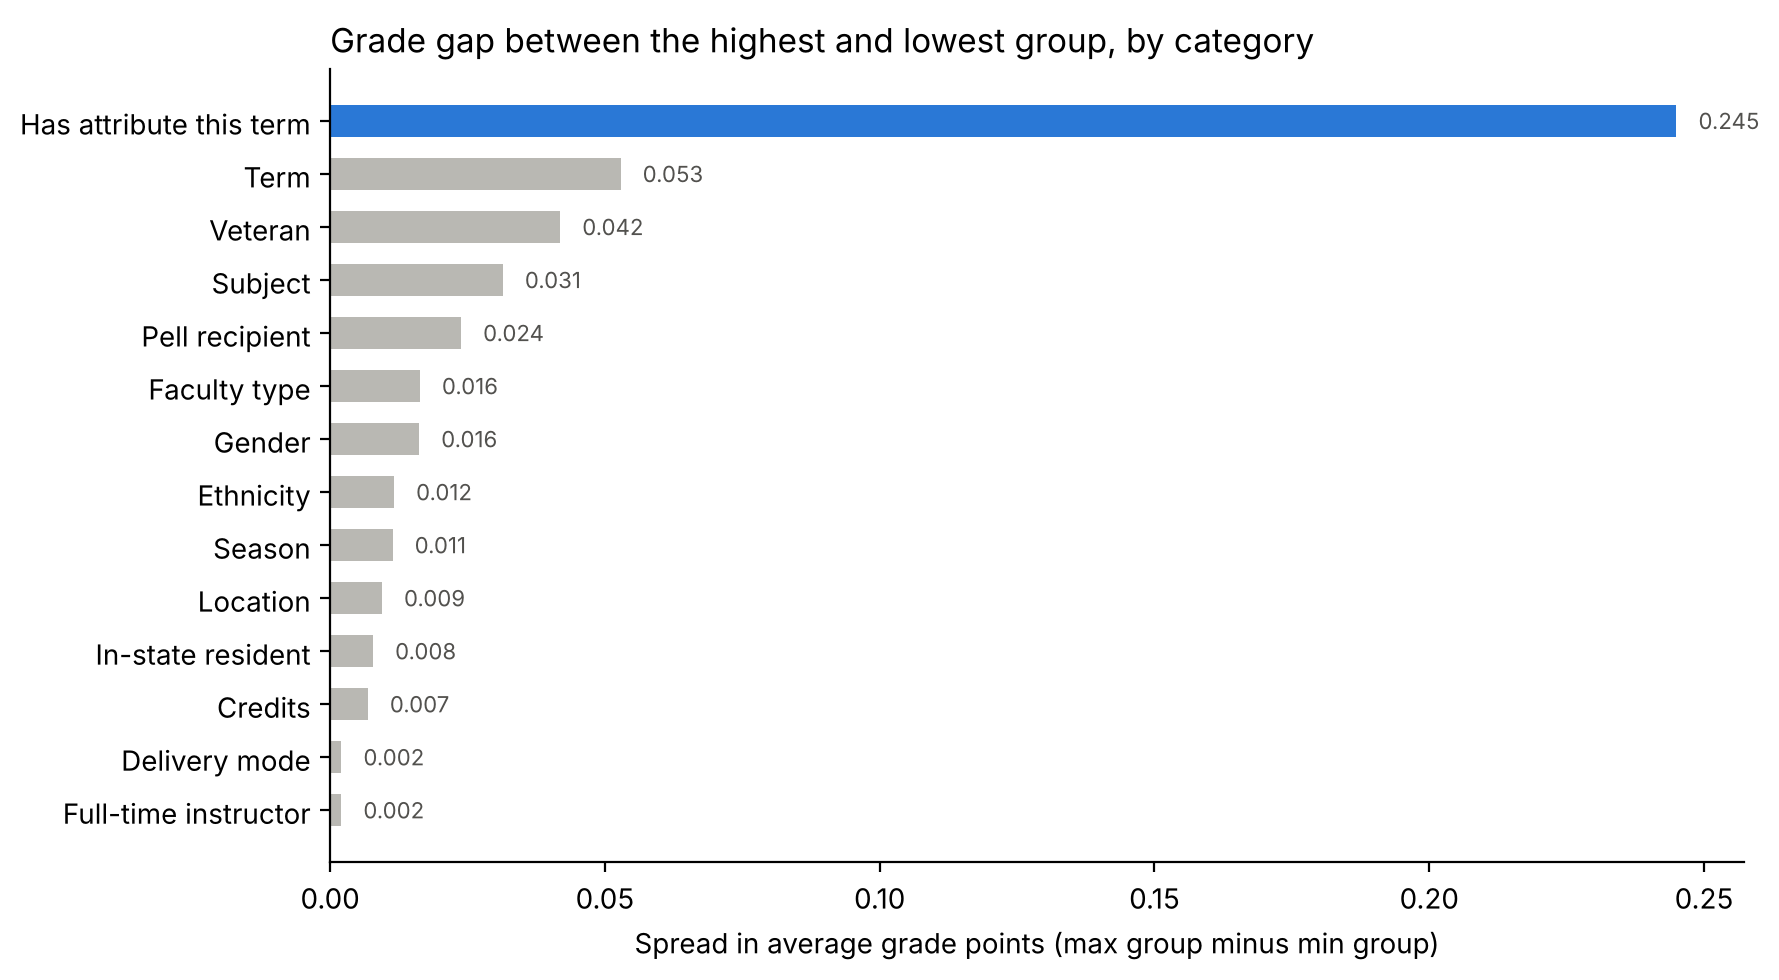

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
s = scan.sort_values("grade_spread")
ax.barh(s["dimension"], s["grade_spread"],
        color=np.where(s["dimension"] == "Has attribute this term", "#2a78d6", "#b9b8b3"), height=0.6)
for y, v in enumerate(s["grade_spread"]):
    ax.text(v + 0.004, y, f"{v:.3f}", va="center", fontsize=8, color="#52514e")
ax.set_title("Grade gap between the highest and lowest group, by category", loc="left")
ax.set_xlabel("Spread in average grade points (max group minus min group)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

Almost every category has a gap under 0.05 grade points, which is effectively no difference. (Term and subject are a bit wider partly because they have more groups and some are small.) **Whether the student holds an attribute that term** clearly stands out at about 0.25 points, roughly 5–10× anything else. That's the question I pursued.

Individual instructors are also very similar: their average grades range only from about 2.79 to 2.93 (standard deviation about 0.03), so there's no evidence of unusually hard or easy graders.

### Step 3: Is it the term or the student?

There are two very different explanations for the gap:
- **(a) Term effect:** holding an attribute (e.g. being in an athletic season, or newly in ESL) lowers grades *in that term*.
- **(b) Student effect:** the students who receive attributes are different students, and they earn different grades in *every* term.

To tell these apart, I split grades into three groups: students who never had an attribute, and students who did, in terms with and without one. Then I **compared each student with themselves**: for students who have both kinds of terms, I compared their grades in terms with an attribute to their grades in terms without one. A paired t-test checks whether the difference is real or just chance.

In [13]:
ever_ids = set(attrs["student_id"])
enroll["ever_attr"] = enroll["student_id"].isin(ever_ids)

three_way = (enroll
    .assign(group=np.select(
        [~enroll.ever_attr, enroll.ever_attr & ~enroll.has_attr_this_term, enroll.has_attr_this_term],
        ["Never had an attribute", "Ever had one: term WITHOUT attribute", "Ever had one: term WITH attribute"], default=""))
    .groupby("group").agg(grades=("grade", "count"), avg_grade=("grade", "mean"), withdrawal_rate=("withdrawal", "mean")))
display(three_way.round(3))

# Compare each student with themselves
paired = (enroll[enroll.ever_attr].dropna(subset=["grade"])
          .groupby(["student_id", "has_attr_this_term"])["grade"].mean().unstack().dropna())
diff = paired[True] - paired[False]
t_stat, p_val = stats.ttest_rel(paired[True], paired[False])
print(f"Students with both kinds of terms: {len(paired):,}")
print(f"Average difference for the same student (attribute term minus non-attribute term): {diff.mean():+.3f} grade points")
print(f"Paired t-test: t = {t_stat:.2f}, p = {p_val:.2f}")

,grades,avg_grade,withdrawal_rate
group,,,
Ever had one: term WITH attribute,8411,2.673,0.048
Ever had one: term WITHOUT attribute,11150,2.720,0.050
Never had an attribute,27942,2.997,0.050


Students with both kinds of terms: 1,058
Average difference for the same student (attribute term minus non-attribute term): -0.002 grade points
Paired t-test: t = -0.20, p = 0.84


The answer is **(b)**. Students who ever had an attribute earn about 2.7 whether or not they hold an attribute in that particular term, and comparing the same student to themselves shows essentially zero difference (p ≈ 0.8). The gap is about *who* these students are, not something that happens in the term the flag is active.

So I should look at **students**, not terms. Next I look at each student's average grade across all their terms.

### Step 4: Look at the distribution, not just the average

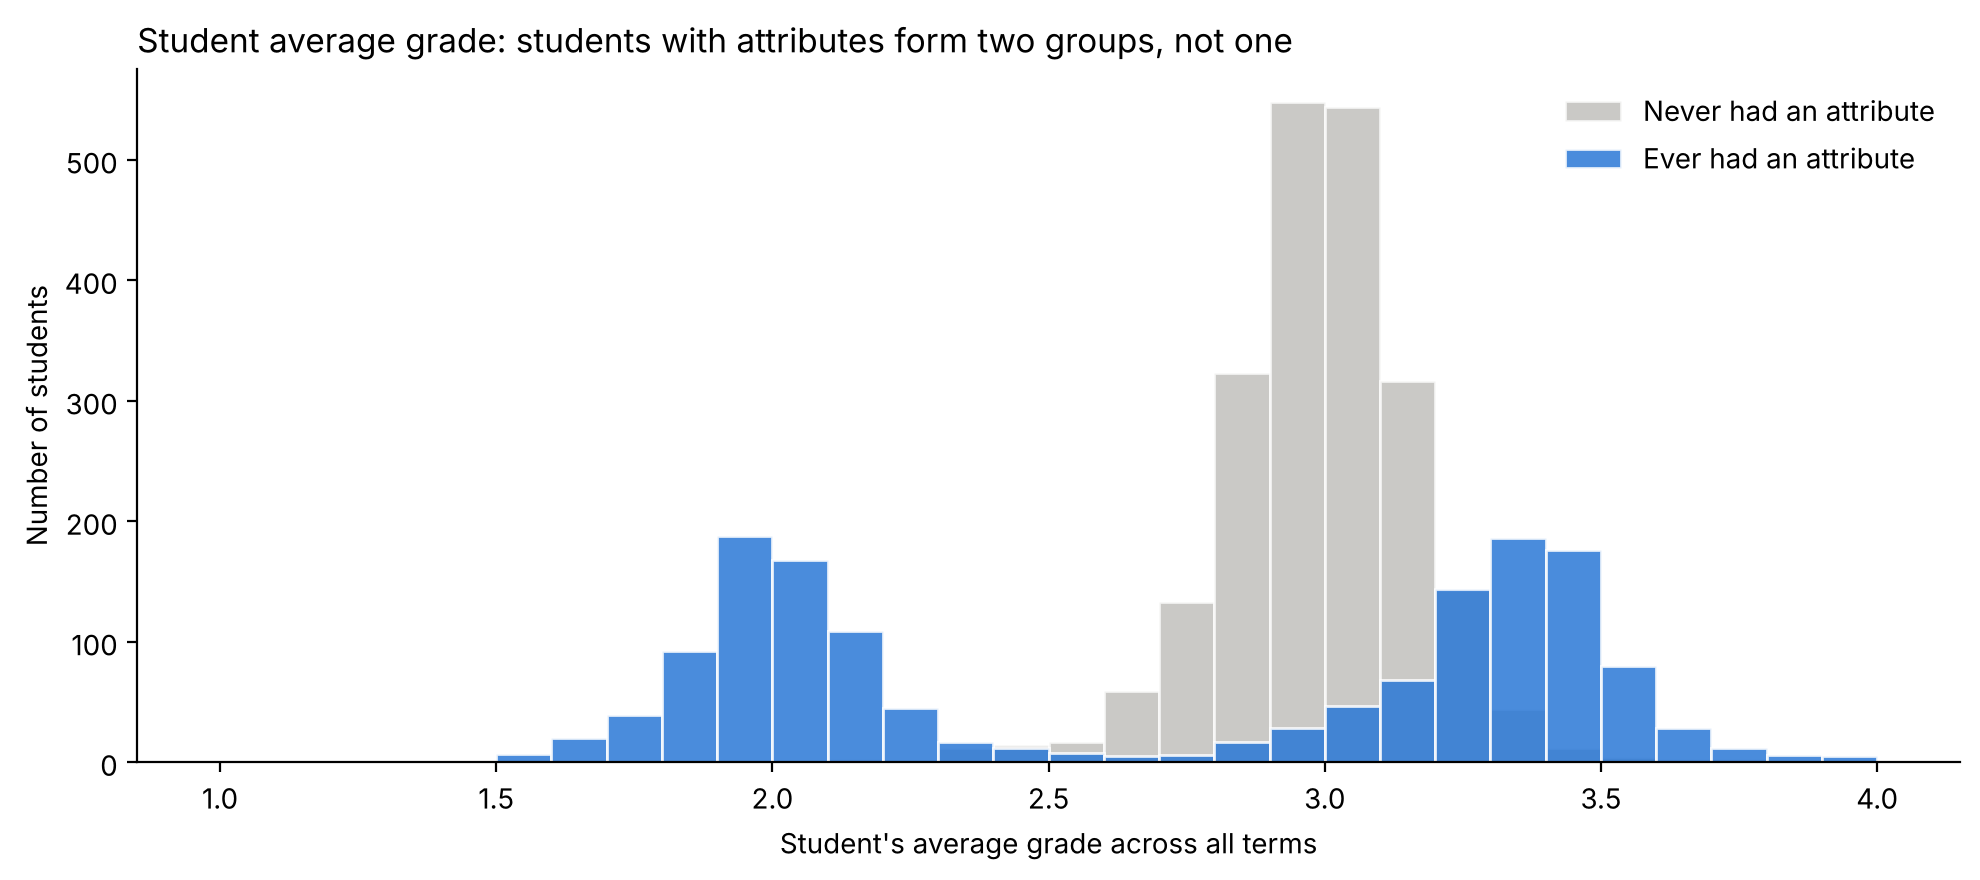

In [14]:
student_gpa = (enroll.dropna(subset=["grade"]).groupby("student_id")
               .agg(gpa=("grade", "mean")).reset_index())
student_gpa["ever_attr"] = student_gpa["student_id"].isin(ever_ids)

fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.linspace(1, 4, 31)
ax.hist(student_gpa.loc[~student_gpa.ever_attr, "gpa"], bins=bins, alpha=0.75, color="#b9b8b3",
        label="Never had an attribute", edgecolor="white", linewidth=1)
ax.hist(student_gpa.loc[student_gpa.ever_attr, "gpa"], bins=bins, alpha=0.85, color="#2a78d6",
        label="Ever had an attribute", edgecolor="white", linewidth=1)
ax.set_title("Student average grade: students with attributes form two groups, not one", loc="left")
ax.set_xlabel("Student's average grade across all terms")
ax.set_ylabel("Number of students")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

This is the key picture. Students without attributes form one tight cluster around 3.0. Students with attributes form **two separate groups**: one around 2.0 and another around 3.4. Their average (about 2.7) falls in the gap between the two peaks, where very few students actually are. The single "attribute students average 2.7" number hides this.

**Do demographics explain which group a student is in?** I split attribute students at 2.6, the dip between the two peaks, and compared the low and high groups on each demographic. For each one, the table shows the largest gap in share between the two groups.

In [15]:
demo = pd.read_sql("SELECT student_id, gender, ethnicity, pell_recipient, us_veteran, state_resident FROM student_main", engine)
att = student_gpa[student_gpa.ever_attr].merge(demo, on="student_id")
att["group"] = np.where(att["gpa"] < 2.6, "Low (~2.0)", "High (~3.4)")
print(att["group"].value_counts().to_string(), "\n")

rows = []
for col in ["gender", "ethnicity", "pell_recipient", "us_veteran", "state_resident"]:
    share = pd.crosstab(att[col], att["group"], normalize="columns")
    rows.append({"characteristic": col,
                 "largest_gap_pct_points": 100 * (share["Low (~2.0)"] - share["High (~3.4)"]).abs().max()})
display(pd.DataFrame(rows).round(1))

group
High (~3.4)    808
Low (~2.0)     707 



,characteristic,largest_gap_pct_points
0,gender,3.9
1,ethnicity,1.9
2,pell_recipient,0.6
3,us_veteran,2.1
4,state_resident,2.4


No. The low and high groups differ by at most about 4 percentage points on any demographic, so demographics don't explain the split. Something else does, which Step 5 looks at.

### Step 5: Which attributes drive each cluster?

Most attribute holders cycle through many different attributes over their terms (half of them hold all ten at some point), so I can't just label each student with "their" attribute. Instead I grouped students by whether they were **ever** flagged ESL or Honors, the two attributes most likely to relate to grades, and compared them with everyone else.

,students,avg_gpa,median_gpa,share_below_2_6
segment,,,,
ESL (no Honors),116,2.002,1.987,0.991
Both ESL and Honors,1183,2.696,2.818,0.496
No attributes,2185,2.991,2.996,0.023
Other attributes only,103,3.009,3.017,0.029
Honors (no ESL),113,3.355,3.388,0.018


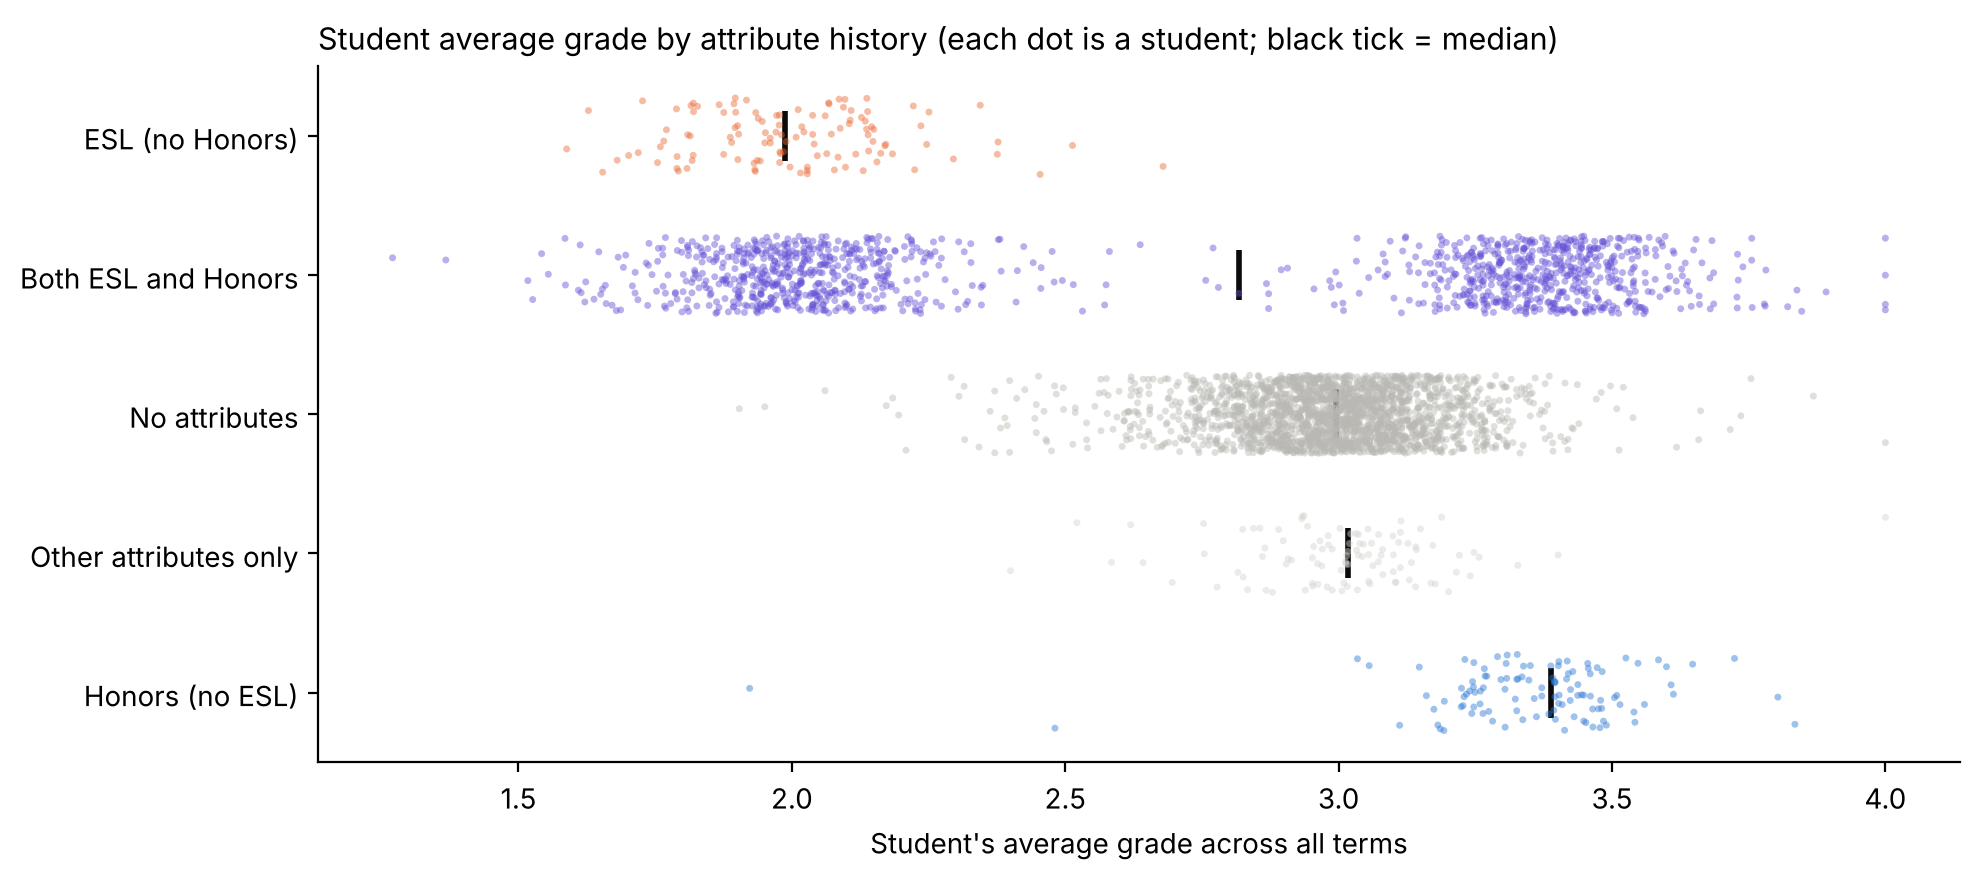

In [16]:
ever_code = attrs.assign(v=1).pivot_table(index="student_id", columns="attribute_code", values="v", aggfunc="max", fill_value=0)
sg = student_gpa.merge(ever_code, left_on="student_id", right_index=True, how="left").fillna({c: 0 for c in ever_code.columns})

def segment(r):
    if r["ESL"] and r["HNR"]: return "Both ESL and Honors"
    if r["ESL"]:              return "ESL (no Honors)"
    if r["HNR"]:              return "Honors (no ESL)"
    if r[ever_code.columns].sum() > 0: return "Other attributes only"
    return "No attributes"

sg["segment"] = sg.apply(segment, axis=1)
order = ["ESL (no Honors)", "Both ESL and Honors", "No attributes", "Other attributes only", "Honors (no ESL)"]
seg_summary = (sg.groupby("segment").agg(students=("gpa", "size"), avg_gpa=("gpa", "mean"), median_gpa=("gpa", "median"),
                                         share_below_2_6=("gpa", lambda x: (x < 2.6).mean()))
               .reindex(order))
display(seg_summary.round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
palette = {"ESL (no Honors)": "#eb6834", "Both ESL and Honors": "#6250d6", "No attributes": "#b9b8b3",
           "Other attributes only": "#d4d3cf", "Honors (no ESL)": "#2a78d6"}
sns.stripplot(data=sg, x="gpa", y="segment", order=order, hue="segment", palette=palette,
              size=2.5, alpha=0.45, jitter=0.28, legend=False, ax=ax)
sns.pointplot(data=sg, x="gpa", y="segment", order=order, estimator="median", errorbar=None,
              color="#0b0b0b", markers="|", markersize=18, linestyles="none", ax=ax)
ax.set_title("Student average grade by attribute history (each dot is a student; black tick = median)", loc="left", fontsize=11)
ax.set_xlabel("Student's average grade across all terms"); ax.set_ylabel("")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

This resolves it. Students who were ever **ESL** average about **2.0**, and nearly all are below 2.6. Students who were ever **Honors** average about **3.4**, and nearly all are above it. Students with **both** split about 50/50 between the two groups.

The eight other attributes (Athlete, International, Transfer, Disability Services, and so on) show **no grade difference** from the general population. The entire "attribute gap" comes from ESL students scoring low, partly offset by Honors students scoring high.

## Caveats and next steps

The findings are summarized at the top of this section. Before acting on them, keep these limits in mind.

**Caveats**
- **Attribute data looks odd.** Many students hold all ten attributes at different points, including both ESL *and* Honors, and attributes change every term. In a real system I'd ask the data owner how attributes are assigned. Do they mean a student is in a program that term, or something else? The "Both ESL and Honors" group (about 1,200 students) especially needs explaining.
- **Coverage.** Only about 3,700 of 10,000 students have grade records.
- **This shows who, not why.** The analysis shows *who* struggles, not *why*. Being ESL may be linked to other things (like how recently a student arrived, or which courses they're placed in).
- The data is synthetic, so some patterns (for example, near-identical results across instructors) probably come from how the fake data was made.

**What I'd do next with more time or real data**
1. Clarify the attribute definitions with the data owner, then rebuild the groups around a clear definition.
2. Break the ESL gap down by subject and course level. If it's concentrated in writing-heavy courses, that points to language support rather than general academic preparation.
3. Track outcomes over time (staying enrolled, credits completed, time to graduate) for ESL students, and test whether any support program correlates with improvement.
4. Turn this comparison into a regular report so advisors can see these groups each term.

# Finish

### Submission Instructions
Once you are finished with the analysis, please save the notebook and email the link to Isaac at ikerson@gsu.edu. If you have any questions or need assistance, feel free to contact Isaac.

We appreciate your time and effort. Good luck, and we look forward to discussing your work!